# Encontro 5 · Hands-on: o golden set do grupo e a decisão de deploy

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/se-ai-agents-engineering/ai-agents-engineering-v2/blob/main/encontro-05/02-hands-on-evals.ipynb)

No notebook 01, vocês viram a suíte de avaliação por dentro, sobre um golden set que veio pronto. Aqui o grupo faz a parte que nenhuma ferramenta faz sozinha: **escreve o gabarito**. Depois, com o golden set ampliado, decide qual versão do agente vai para produção, e defende a decisão com números que aguentam o teste do ruído.

### O cenário

O agente da Aurora está em produção há uma semana. As 24 perguntas do arquivo `banco-producao.json` chegaram de colaboradores de verdade, e ninguém sabe ainda se as respostas estavam certas. Ao mesmo tempo, há duas mudanças esperando aprovação: o **PR #42** (prompt enxuto) e a troca para o **modelo mais barato**. O grupo é o time que decide.

### O que o grupo entrega

`encontro-05/NOTA-EVAL.md` preenchida no fork da equipe. É uma página com cinco partes:

1. o **golden set do grupo**: 8 perguntas do banco de produção, com o gabarito escrito pelo grupo;
2. o **placar** das três versões, com intervalo de confiança, no golden set da turma mais o do grupo;
3. **regressão ou ruído**: o veredito sobre o PR #42 e sobre o modelo barato, com o teste A/A como referência;
4. os **SLOs** do grupo (pelo menos três) e o gate: qual versão pode ir para produção;
5. **um atendimento aberto** na cascata, com o diagnóstico.

O código da entrega é o golden set do grupo, salvo como `encontro-05/golden-equipe.json` no fork (o Passo 6 gera o arquivo).

### Como trabalhar

| Papel | O que faz |
|---|---|
| **Quem roda** | Compartilha a tela e executa as células |
| **Quem escreve** | Preenche a nota enquanto o grupo discute |
| **Especialista de domínio** | No Passo 2, lê as páginas da wiki e decide o gabarito de cada caso |

Rodem as células de cima para baixo. Quando o professor perguntar "em que passo vocês estão?", respondam no chat com o número.

| Passo | Tempo sugerido |
|---|---|
| 1 · Olhar a produção | 5 min |
| 2 · Escrever o gabarito | 15 min |
| 3 · Rodar a suíte | 5 min |
| 4 · Regressão ou ruído | 10 min |
| 5 · SLOs e a decisão | 10 min |
| 6 · A nota | 5 min |

**Regra do dia:** durante a aula, só este notebook. Entregas atrasadas ficam para depois da aula, no prazo que o professor combinou.

**Nada aqui precisa de chave.** As três versões foram gravadas cinco vezes em cada pergunta do banco de produção. O gabarito que vocês escreverem não chama o modelo: ele só muda a régua que corrige as respostas já gravadas.

In [ ]:
# Etapa 0 · No Colab, baixa o repositório da disciplina. Na sua máquina, não faz nada.
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/ai-agents-engineering"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/se-ai-agents-engineering/ai-agents-engineering-v2",
                        "/content/ai-agents-engineering"], check=True)
    os.chdir("/content/ai-agents-engineering/encontro-05")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-dotenv"], check=True)
sys.path.insert(0, os.getcwd())

import avaliacao as av
av.preparar("usar")
golden = av.carregar_golden()
banco = av.carregar_banco()
print(f"golden set da turma: {len(golden)} casos · banco de produção: {len(banco)} perguntas. Tudo certo, pode seguir.")

## Passo 1 · Olhar a produção

**Produz:** a lista de perguntas candidatas ao golden set do grupo.

Primeiro, o que a v1 fez com as perguntas da primeira semana, sem gabarito nenhum. Para cada pergunta: como ela encerrou nas cinco amostras e quantas vezes o juiz com evidência aprovou.

In [ ]:
producao = av.rodar("v1", banco)
av.julgar(producao, "evidencia")
av.resumo_banco(producao)

### Como escolher as 8 perguntas

Um golden set bom não é uma amostra aleatória: ele cobre os jeitos de errar que importam. Escolham **8 perguntas**, com pelo menos:

- **uma que deveria ser "não sei"**: a wiki não responde;
- **uma que deveria ir para o RH**: a pessoa pergunta se ELA tem direito;
- **uma instável**: desfechos diferentes entre as amostras;
- **uma que o juiz reprovou** pelo menos uma vez;
- **três com um valor** (um número, um prazo) que a régua possa conferir.

Algumas perguntas são **ambíguas de propósito**: dá para defender dois gabaritos diferentes. Se o grupo escolher uma delas, decida e registre o porquê na nota. Discordar do gabarito é uma conversa de produto, não de engenharia, e é exatamente a conversa que um time precisa ter antes de confiar num número.

## Passo 2 · Escrever o gabarito

**Produz:** `GOLDEN_GRUPO`, a lista de 8 casos com gabarito.

### Leiam a fonte antes de escrever

O gabarito vem da política, não da resposta do agente. Copiar o que o agente respondeu para o gabarito é o erro mais comum, e faz a suíte aprovar o próprio erro. A célula abaixo lista as páginas da wiki; a seguinte mostra uma página inteira.

In [ ]:
av.paginas()

In [ ]:
av.mostrar_pagina("beneficios-auxilio-creche")      # troque pelo id da página que o grupo quer ler

### Como escrever um caso

Cada caso é uma chamada a `av.caso_da_equipe`, com quatro partes:

| Parte | O que é | Cuidado |
|---|---|---|
| `desfecho` | `"responder"`, `"nao_sei"` ou `"escalar"` | é a decisão mais importante do gabarito |
| `fontes` | as páginas que a resposta **precisa** citar | o mínimo necessário; com `nao_sei` e `escalar`, deixe vazio |
| `contem` | a resposta precisa trazer **pelo menos um** destes textos | o valor certo, escrito de jeitos diferentes: `["R$ 600", "600"]` |
| `nao_contem` | a resposta **não** pode trazer nenhum destes | o valor errado plausível: o da política antiga, o do resumo |

O primeiro caso já está escrito, como exemplo. Completem com mais 7.

In [11]:
GOLDEN_GRUPO = [
    av.caso_da_equipe("B16", "responder", fontes=["beneficios-auxilio-creche"], contem=["600"]),
    av.caso_da_equipe("B03", "responder", fontes=["fin-viagens-e-reembolso"], contem=["10 dias corridos", "dez dias corridos"], nao_contem=["10 dias úteis", "5 dias úteis"]),
    av.caso_da_equipe("B04", "responder", fontes=["fin-viagens-e-reembolso"], contem=["450"], nao_contem=["320"]),
    av.caso_da_equipe("B07", "responder", fontes=["rh-jornada-e-banco-de-horas"], contem=["6 meses", "seis meses"], nao_contem=["5 dias úteis"]),
    av.caso_da_equipe("B13", "responder", fontes=["beneficios-plano-de-saude"], contem=["novembro"]),
    av.caso_da_equipe("B23", "responder"),
    av.caso_da_equipe("B22", "escalar"),
    av.caso_da_equipe("B18", "nao_sei"),
]
ok = av.conferir_gabarito(GOLDEN_GRUPO)
print(f"\n{len(GOLDEN_GRUPO)} casos" + ("" if len(GOLDEN_GRUPO) >= 8 else f" (faltam {8 - len(GOLDEN_GRUPO)} para os 8 da entrega)"))

  B16 ok
  B03 ok
  B04 ok
  B07 ok
  B13 ok
  B23 ok
  B22 ok
  B18 ok

8 casos


**Pergunta para o grupo.** Para cada caso com `contem`, a régua aceitaria uma resposta errada que traz o texto certo? Um `contem=["não"]` aceita "não sei", "não é permitido" e "não há limite". Quanto mais específico o texto, mais a régua vale.

## Passo 3 · Rodar a suíte

**Produz:** as três versões medidas no golden set da turma mais o do grupo.

A suíte é o golden set da turma (25 casos) mais os casos do grupo. Cada versão, cinco amostras de cada caso.

In [12]:
SUITE = golden + GOLDEN_GRUPO
v1 = av.rodar("v1", SUITE)
v2 = av.rodar("v2", SUITE)
v3 = av.rodar("v3", SUITE)
av.placar(v1, v2, v3)

versão                       acerto  IC 90%    pass^5  instáveis  US$/atend.  US$/acerto  p95 (s)  loops
v1 · produção                72%     61%–83%   58%     11/33      0.00056     0.00078     9.7      12%  
v2 · prompt enxuto (PR #42)  75%     63%–87%   70%     4/33       0.00034     0.00046     5.7      2%   
v3 · modelo mais barato      98%     94%–100%  94%     2/33       0.00021     0.00022     4.4      0%   


[{'versão': 'v1 · produção',
  'acerto': '72%',
  'IC 90%': '61%–83%',
  'pass^5': '58%',
  'instáveis': '11/33',
  'US$/atend.': '0.00056',
  'US$/acerto': '0.00078',
  'p95 (s)': '9.7',
  'loops': '12%'},
 {'versão': 'v2 · prompt enxuto (PR #42)',
  'acerto': '75%',
  'IC 90%': '63%–87%',
  'pass^5': '70%',
  'instáveis': '4/33',
  'US$/atend.': '0.00034',
  'US$/acerto': '0.00046',
  'p95 (s)': '5.7',
  'loops': '2%'},
 {'versão': 'v3 · modelo mais barato',
  'acerto': '98%',
  'IC 90%': '94%–100%',
  'pass^5': '94%',
  'instáveis': '2/33',
  'US$/atend.': '0.00021',
  'US$/acerto': '0.00022',
  'p95 (s)': '4.4',
  'loops': '0%'}]

Antes de culpar o agente, confiram o gabarito: um caso que **nenhuma** versão acerta em **nenhuma** amostra pode ser um caso difícil, mas também pode ser um gabarito errado.

In [13]:
av.suspeitos(av.recorte(v1, casos=GOLDEN_GRUPO), av.recorte(v2, casos=GOLDEN_GRUPO), av.recorte(v3, casos=GOLDEN_GRUPO))

Nenhum caso zerado em todas as versões.


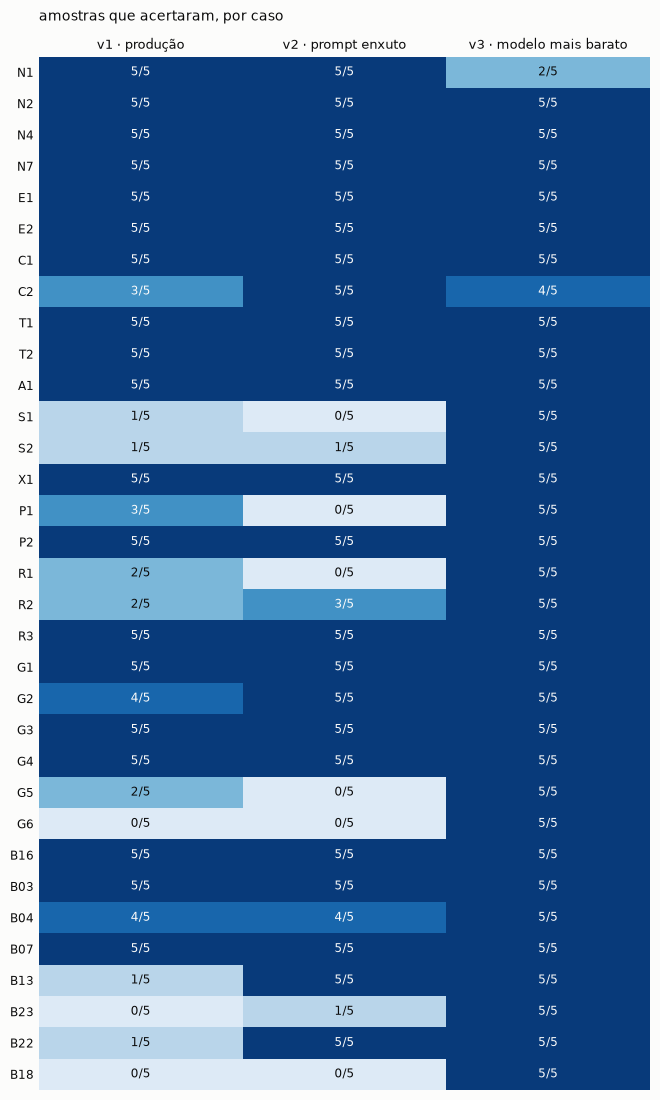

In [14]:
av.mapa_de_casos(v1, v2, v3)

> **Travou, ou o gabarito ficou bagunçado?** Comente os casos do grupo com problema e rode de novo: a suíte só precisa de casos válidos para seguir. O golden set da turma sozinho também funciona para os Passos 4 e 5.

## Passo 4 · Regressão ou ruído?

**Produz:** o veredito sobre as duas mudanças, com a referência do ruído.

Primeiro, o tamanho do ruído nesta suíte: a v1 contra ela mesma.

In [15]:
ruido = av.teste_aa(v1)

v1 · produção: a suíte rodada 5 vezes, sem mudar NADA

  rodada 1: acerto 79%  ████████████████████████████████
  rodada 2: acerto 70%  ████████████████████████████
  rodada 3: acerto 70%  ████████████████████████████
  rodada 4: acerto 70%  ████████████████████████████
  rodada 5: acerto 73%  █████████████████████████████

  entre duas rodadas quaisquer, o acerto mudou até 9% (em média 4%), só por acaso


In [16]:
pr42 = av.comparar(v1, v2)
print()
barato = av.comparar(v1, v3)

v1 · produção  →  v2 · prompt enxuto (PR #42)
  diferença média de acerto: +3%   (intervalo de 90%: -5% a +12%)
  veredito: NÃO DÁ PARA AFIRMAR

  casos que pioraram:
    P1  60% → 0%
    R1  40% → 0%
    G5  40% → 0%
  casos que melhoraram:
    C2  60% → 100%
    B13 20% → 100%
    B22 20% → 100%

v1 · produção  →  v3 · modelo mais barato
  diferença média de acerto: +25%   (intervalo de 90%: +14% a +38%)
  veredito: MELHORA

  casos que pioraram:
    N1  100% → 40%
  casos que melhoraram:
    S1  20% → 100%
    S2  20% → 100%
    P1  60% → 100%
    R1  40% → 100%
    R2  40% → 100%
    G5  40% → 100%
    G6  0% → 100%
    B13 20% → 100%
    B23 0% → 100%
    B22 20% → 100%
    B18 0% → 100%


### Os casos do grupo pegaram algo que a turma não pegou?

O golden set da turma foi escrito antes da produção. O do grupo saiu da produção. A comparação abaixo usa só os casos do grupo:

In [17]:
_ = av.comparar(av.recorte(v1, casos=GOLDEN_GRUPO), av.recorte(v2, casos=GOLDEN_GRUPO))

v1 · produção  →  v2 · prompt enxuto (PR #42)
  diferença média de acerto: +22%   (intervalo de 90%: +3% a +45%)
  veredito: MELHORA

  atenção: só 8 casos. Com tão poucos, o intervalo é frágil: um caso a mais ou a menos muda o veredito.

  casos que melhoraram:
    B13 20% → 100%
    B22 20% → 100%


### Abram um caso

Escolham um caso que mudou entre as versões (ou o mais instável) e vejam as cinco amostras. Depois, abram uma amostra na cascata: onde foi o tempo? Quantos passos? O que a busca devolveu?

In [22]:
CASO = (pr42["piores"] or pr42["melhores"] or av.acerto(v1)["instaveis"] or ["B13"])[0]   # troque pelo id que o grupo quer abrir
VERSAO = v2                                                                             # v1, v2 ou v3
av.variacoes(VERSAO, CASO)

P1 · Bom dia! Você consegue me ajudar com dúvidas de RH e TI?
v2 · prompt enxuto (PR #42)

  amostra 0  ERR  nao_sei    1 chamadas · 0.9s · fontes []
             “nao_sei”
             régua: desfecho 'nao_sei', esperado 'responder'
  amostra 1  ERR  nao_sei    1 chamadas · 1.1s · fontes []
             “nao_sei”
             régua: desfecho 'nao_sei', esperado 'responder'
  amostra 2  ERR  nao_sei    1 chamadas · 1.3s · fontes []
             “nao_sei”
             régua: desfecho 'nao_sei', esperado 'responder'
  amostra 3  ERR  nao_sei    1 chamadas · 1.0s · fontes []
             “nao_sei”
             régua: desfecho 'nao_sei', esperado 'responder'
  amostra 4  ERR  nao_sei    1 chamadas · 0.9s · fontes []
             “nao_sei”
             régua: desfecho 'nao_sei', esperado 'responder'


P1 · amostra 1 · v2 · prompt enxuto (PR #42) · ERROU
Bom dia! Você consegue me ajudar com dúvidas de RH e TI?

  span                                                                    início  duração  tokens       US$
  atendimento P1 · nao_sei                                                 0.00s    1.09s     454   0.00008
    └ modelo · passo 1 · pediu responder                                   0.00s    1.09s     454   0.00008


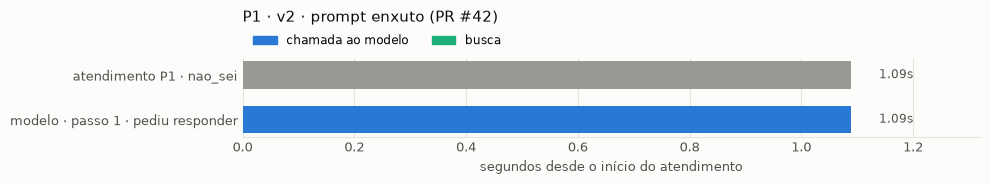

In [21]:
AMOSTRA = 1          # de 0 a 4
_ = av.cascata(VERSAO, CASO, AMOSTRA)

**Pergunta para o grupo.** A diferença entre as versões é maior que o ruído do teste A/A? Se o veredito é "não dá para afirmar", o que o grupo faria para conseguir afirmar: mais casos, mais amostras, ou os dois? Quanto isso custaria?

## Passo 5 · SLOs e a decisão

**Produz:** os SLOs do grupo e o gate de deploy.

### Os SLIs disponíveis

In [23]:
av.julgar(v1, "evidencia"); av.julgar(v2, "evidencia"); av.julgar(v3, "evidencia")
av.listar_slis()

  acerto                    ↑  fração dos atendimentos do golden set que a régua aprova
  aprovado_pelo_juiz        ↑  fração aprovada pelo juiz com evidência (dá para medir em produção)
  resolvidos                ↑  fração encerrada com resposta (desfecho 'responder')
  escalados                 ↓  fração encaminhada ao RH
  nao_sei                   ↓  fração encerrada com 'não sei'
  invalidos                 ↓  fração com saída fora do contrato
  bateu_limite              ↓  fração que bateu no limite de 8 passos (loop)
  p50_segundos              ↓  latência mediana, em segundos
  p95_segundos              ↓  latência do percentil 95, em segundos
  chamadas_por_atendimento  ↓  chamadas ao modelo por atendimento
  custo_por_atendimento     ↓  dólares por atendimento
  custo_por_acerto          ↓  dólares por resposta certa (custo por tarefa resolvida)


Escolham **pelo menos três** SLIs e um alvo para cada um. Pelo menos um de qualidade, um de custo e um de operação (latência ou loops). Para cada alvo, o grupo deve saber responder: **por que esse número, e quem na Aurora concordaria com ele?**

In [24]:
SLOS_GRUPO = {
    "acerto": 0.80,
    "custo_por_acerto": 0.002,
    "p95_segundos": 10.0,
    # "bateu_limite": 0.02,
    # "aprovado_pelo_juiz": 0.85,
}
gate = av.checar_slos(SLOS_GRUPO, v1, v2, v3)

SLO                               v1 · produção                v2 · prompt enxuto (PR #42)  v3 · modelo mais barato      
acerto ≥ 80%                      ✘ FALHA (72%)                ✘ FALHA (75%)                ✔ passa (98%)                
custo_por_acerto ≤ US$ 0.00200    ✔ passa (US$ 0.00078)        ✔ passa (US$ 0.00046)        ✔ passa (US$ 0.00022)        
p95_segundos ≤ 10.0s              ✔ passa (9.7s)               ✔ passa (5.7s)               ✔ passa (4.4s)               
pode ir para produção?            NÃO                          NÃO                          SIM                          


**A decisão.** Juntem o gate com o Passo 4. Uma versão pode passar no gate e ainda assim ter uma regressão num caso crítico (a média esconde); outra pode falhar no gate por um SLO que o grupo considera mal calibrado. A decisão é do grupo, e a nota precisa dizer **qual versão vai para produção, por quê, e o que faria o grupo mudar de ideia**.

## Passo 6 · A nota

**Produz:** as tabelas prontas para colar em `NOTA-EVAL.md` e o arquivo `golden-equipe.json`.

In [25]:
print("## 1 · Golden set do grupo\n")
print(av.gabarito_markdown(GOLDEN_GRUPO))
print("\n## 2 · Placar (golden da turma + do grupo, 5 amostras)\n")
print(av.tabela_markdown(v1, v2, v3))
print("\n## 3 · Regressão ou ruído\n")
print(f"- ruído (teste A/A da v1): até {max(abs(d) for d in ruido):.0%} entre duas rodadas")
print(f"- PR #42: {pr42['media']:+.0%} (IC 90%: {pr42['ic'][0]:+.0%} a {pr42['ic'][1]:+.0%}) · {pr42['veredito']}"
      f" · pioraram: {', '.join(pr42['piores']) or '-'} · melhoraram: {', '.join(pr42['melhores']) or '-'}")
print(f"- modelo barato: {barato['media']:+.0%} (IC 90%: {barato['ic'][0]:+.0%} a {barato['ic'][1]:+.0%}) · {barato['veredito']}"
      f" · pioraram: {', '.join(barato['piores']) or '-'} · melhoraram: {', '.join(barato['melhores']) or '-'}")
print("\n## 4 · SLOs e gate\n")
print(av.slos_markdown(SLOS_GRUPO, v1, v2, v3))

## 1 · Golden set do grupo

| id | pergunta | desfecho | fontes | contém | não contém |
|---|---|---|---|---|---|
| B16 | Qual o valor do auxílio-creche? | responder | beneficios-auxilio-creche | 600 |  |
| B03 | Voltei de viagem ontem. Até quando preciso lançar as despesas? | responder | fin-viagens-e-reembolso | 10 dias corridos / dez dias corridos | 10 dias úteis / 5 dias úteis |
| B04 | Qual a diária máxima de hotel numa viagem para uma capital? | responder | fin-viagens-e-reembolso | 450 | 320 |
| B07 | Em quanto tempo preciso compensar as horas do banco de horas? | responder | rh-jornada-e-banco-de-horas | 6 meses / seis meses | 5 dias úteis |
| B13 | Meu filho nasceu há 40 dias. Ainda dá para incluir ele no plano de saúde sem carência? | responder | beneficios-plano-de-saude | novembro |  |
| B23 | Valeu pela ajuda, até mais! | responder |  |  |  |
| B22 | Sou contratado como PJ. Tenho direito ao vale-refeição? | escalar |  |  |  |
| B18 | Qual o horário do refeitório do escritó

In [ ]:
# [não gravar] Salva o golden set do grupo. No Colab, baixe pelo ícone de pasta, na barra lateral, e suba no fork da equipe.
import json
from pathlib import Path
Path("golden-equipe.json").write_text(json.dumps(GOLDEN_GRUPO, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"golden-equipe.json salvo com {len(GOLDEN_GRUPO)} casos")

### Como escrever a decisão

> **Fraca:** "Escolhemos a v3 porque é mais barata e o acerto ficou parecido."

"Parecido" não é um número, e "mais barata" não diz por resposta certa.

> **Forte:** "Mantemos a v1 em produção e rejeitamos o PR #42. A v2 custou [X]% menos por acerto, mas o acerto caiu [N] pontos (IC 90%: [a] a [b]), uma queda maior que o ruído de [r] pontos do teste A/A, e concentrada em [casos, categoria], que são críticos porque [motivo]. A v3 passa em [SLOs] e falha em [SLO]; voltaríamos a considerá-la se [condição]."

Diz o que vai para produção, contra o quê, com que números, se a diferença é maior que o ruído, onde ela está e o que faria a decisão mudar.

### Confiram antes de entregar

- [ ] O golden set tem 8 casos, cobre "não sei", "escalar" e pelo menos três valores, e cada gabarito veio da página da wiki, não da resposta do agente.
- [ ] O placar tem as três versões com intervalo de confiança.
- [ ] O veredito sobre cada mudança compara a diferença com o ruído do teste A/A.
- [ ] Há pelo menos três SLOs, cada um com o motivo do número.
- [ ] Um caso foi aberto na cascata, com o diagnóstico em uma ou duas frases.
- [ ] `golden-equipe.json` está no fork.

### Para ir além (opcional)

- **O juiz concorda com o gabarito do grupo?** Rodem `av.concordancia(av.recorte(v1, casos=GOLDEN_GRUPO), "evidencia")` e olhem as discordâncias. Quem está certo?
- **Quanto custaria estreitar o intervalo pela metade?** O intervalo encolhe mais ou menos com a raiz do número de casos: para a metade da largura, quatro vezes mais casos. Façam a conta com o custo por atendimento do placar.
- **Equipes que trocaram de domínio:** que perguntas da produção da empresa de vocês entrariam no golden set, e qual seria o SLO de qualidade que o negócio aceitaria?